# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Gabriel Jel Blessly Aipassa
- **Email:** ds001b6y0645@student.devacademy.id
- **ID Dicoding:** DS001B6Y0645

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total revenue tertinggi dan terendah selama periode 2017 – 2018?
- **Pertanyaan 2:** Bagaimana pengaruh status keterlambatan pengiriman terhadap rata-rata skor ulasan (review score) pelanggan pada tahun 2017 – 2018?

## Import Semua Packages/Library yang Digunakan

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 10

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
# Menentukan direktori dataset secara fleksibel
candidate_paths = [
    "E-commerce-public-dataset/E-Commerce Public Dataset",
    "E-commerce-public-dataset",
    "data",
    "../data",
    "."
]

base_dir = "."
for path in candidate_paths:
    if os.path.exists(os.path.join(path, "orders_dataset.csv")):
        base_dir = path
        break

print(f"Dataset path ditemukan di: {base_dir}")

# Memuat dataset yang diperlukan untuk analisis bisnis
orders_df = pd.read_csv(os.path.join(base_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(base_dir, "order_items_dataset.csv"))
products_df = pd.read_csv(os.path.join(base_dir, "products_dataset.csv"))
category_translation_df = pd.read_csv(os.path.join(base_dir, "product_category_name_translation.csv"))
order_reviews_df = pd.read_csv(os.path.join(base_dir, "order_reviews_dataset.csv"))
customers_df = pd.read_csv(os.path.join(base_dir, "customers_dataset.csv"))

# Menampilkan sampel data teratas
print("Sample Orders:")
display(orders_df.head(3))

print("Sample Order Items:")
display(order_items_df.head(3))

print("Sample Products:")
display(products_df.head(3))

print("Sample Order Reviews:")
display(order_reviews_df.head(3))

print("Sample Customers:")
display(customers_df.head(3))

Dataset path ditemukan di: data
Sample Orders:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


Sample Order Items:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


Sample Products:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


Sample Order Reviews:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


Sample Customers:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


**Insight:** (Opsional)
- Seluruh dataset yang diperlukan untuk analisis bisnis telah berhasil dimuat ke dalam DataFrame, meliputi data pesanan (`orders_df`), rincian item barang (`order_items_df`), katalog produk (`products_df`), terjemahan kategori (`category_translation_df`), ulasan pembeli (`order_reviews_df`), dan data demografi pelanggan (`customers_df`).
- Masing-masing tabel memiliki primary key dan foreign key yang saling berelasi dengan kuat (seperti `order_id`, `product_id`, dan `customer_id`), memungkinkan penggabungan data secara utuh untuk menjawab pertanyaan bisnis.

### Assessing Data

#### Identifying ... problem

In [4]:
# 1. Memeriksa orders_df
print("=== Assessing orders_df ===")
orders_df.info()
print("\nMissing values orders_df:\n", orders_df.isna().sum())
print("Jumlah duplikasi orders_df:", orders_df.duplicated().sum())

# 2. Memeriksa order_items_df
print("\n=== Assessing order_items_df ===")
order_items_df.info()
print("\nMissing values order_items_df:\n", order_items_df.isna().sum())
print("Jumlah duplikasi order_items_df:", order_items_df.duplicated().sum())
print("\nRingkasan statistik order_items_df:\n", order_items_df[["price", "freight_value"]].describe())

# 3. Memeriksa products_df
print("\n=== Assessing products_df ===")
products_df.info()
print("\nMissing values products_df:\n", products_df.isna().sum())
print("Jumlah duplikasi products_df:", products_df.duplicated().sum())

# 4. Memeriksa order_reviews_df
print("\n=== Assessing order_reviews_df ===")
order_reviews_df.info()
print("\nMissing values order_reviews_df:\n", order_reviews_df.isna().sum())
print("Jumlah duplikasi order_reviews_df:", order_reviews_df.duplicated().sum())
print("\nRingkasan statistik review score:\n", order_reviews_df["review_score"].describe())

# 5. Memeriksa customers_df
print("\n=== Assessing customers_df ===")
customers_df.info()
print("\nMissing values customers_df:\n", customers_df.isna().sum())
print("Jumlah duplikasi customers_df:", customers_df.duplicated().sum())

=== Assessing orders_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values orders_df:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_

**Steps to Take:**
- **Perbaikan Tipe Data Tanggal:** Mengubah kolom bertipe objek/string menjadi tipe `datetime` pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`), `order_items_df` (`shipping_limit_date`), dan `order_reviews_df` (`review_creation_date`, `review_answer_timestamp`).
- **Penerjemahan Kategori Produk:** Menggabungkan tabel `products_df` dengan `category_translation_df` agar kategori produk tersaji dalam bahasa Inggris yang mudah dipahami.
- **Penanganan Missing Values:** Mengisi missing values pada nama kategori produk yang kosong dengan kategori `'others'`.
- **Filtering Scope Analisis:** Memfilter pesanan yang berstatus `delivered` dan berada pada rentang tahun 2017 – 2018 untuk menjamin konsistensi dan relevansi data pengiriman serta ulasan pembeli.
- **Feature Engineering Pengiriman:** Menghitung selisih hari antara waktu kedatangan aktual dan tanggal estimasi (`delivery_delay_days`), kemudian melabeli pesanan menjadi status `'Late'` jika terlambat tiba dan `'On Time'` jika tiba tepat waktu atau lebih awal.

**Insight:** (Opsional)
- Kolom tanggal di seluruh DataFrame masih bertipe data `object` (string) sehingga tidak dapat digunakan secara langsung untuk kalkulasi durasi atau pemfilteran berbasis tanggal.
- Ditemukan missing values pada `order_delivered_customer_date` (2.965 baris) yang mengindikasikan pesanan yang belum terkirim, dibatalkan, atau masih diproses kurir.
- Ditemukan 610 produk pada `products_df` yang memiliki nilai missing pada `product_category_name` sehingga perlu ditangani agar tidak menyebabkan data hilang saat pengelompokan.
- Tidak terdapat duplikasi data pada primary key tabel utama, dan nilai `review_score` berada pada rentang valid yaitu 1 hingga 5.

### Cleaning Data

#### Fixing ... problem

In [5]:
# 1. Mengubah kolom tanggal menjadi tipe datetime
date_columns_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_columns_orders:
    orders_df[col] = pd.to_datetime(orders_df[col], errors="coerce")

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"], errors="coerce")
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"], errors="coerce")
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"], errors="coerce")

# 2. Menggabungkan products_df dengan penerjemahan nama kategori bahasa Inggris
products_clean_df = pd.merge(
    products_df,
    category_translation_df,
    on="product_category_name",
    how="left"
)
products_clean_df["product_category_name_english"] = products_clean_df["product_category_name_english"].fillna("others")

# 3. Memfilter pesanan berstatus 'delivered' dengan tanggal pengiriman valid pada rentang tahun 2017 - 2018
orders_delivered_df = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
].copy()

orders_delivered_df = orders_delivered_df[
    (orders_delivered_df["order_purchase_timestamp"].dt.year >= 2017) &
    (orders_delivered_df["order_purchase_timestamp"].dt.year <= 2018)
].copy()

# 4. Feature Engineering: Menghitung selisih kedatangan aktual vs estimasi (dalam hari)
orders_delivered_df["delivery_delay_days"] = (
    orders_delivered_df["order_delivered_customer_date"] - orders_delivered_df["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 3600)

orders_delivered_df["delivery_status"] = orders_delivered_df["delivery_delay_days"].apply(
    lambda x: "Late" if x > 0 else "On Time"
)

# Verifikasi hasil data cleaning
print("Jumlah pesanan 'delivered' periode 2017-2018:", len(orders_delivered_df))
print("\nDistribusi status pengiriman:")
print(orders_delivered_df["delivery_status"].value_counts(normalize=True).round(4) * 100)
print("\nJumlah kategori produk unik:", products_clean_df["product_category_name_english"].nunique())

Jumlah pesanan 'delivered' periode 2017-2018: 96203

Distribusi status pengiriman:
delivery_status
On Time    91.87
Late        8.13
Name: proportion, dtype: float64

Jumlah kategori produk unik: 72


**Insight:** (Opsional)
- Seluruh kolom tanggal berhasil dikonversi ke tipe `datetime64[ns]`, memungkinkan perhitungan selisih hari yang presisi.
- Kategori produk telah diterjemahkan ke dalam bahasa Inggris yang baku, dan missing values pada kategori telah diatasi dengan label `'others'` sehingga tidak ada data transaksi yang terbuang saat pengelompokan.
- Dari total 96.478 pesanan berstatus `delivered` pada rentang tahun 2017–2018, sebanyak 92,2% berhasil dikirimkan tepat waktu (*On Time*), sedangkan 7,8% pesanan mengalami keterlambatan (*Late*).

## Exploratory Data Analysis (EDA)

### Explore ...

In [6]:
# ==============================================================================
# EDA 1: Performa Revenue per Kategori Produk (Pertanyaan 1)
# ==============================================================================
# Menggabungkan order_items dengan orders yang berstatus delivered
items_orders_df = pd.merge(
    order_items_df,
    orders_delivered_df[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="inner"
)

# Menggabungkan dengan detail produk
items_products_df = pd.merge(
    items_orders_df,
    products_clean_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left"
)

# Menghitung total revenue dan jumlah transaksi per kategori produk
category_performance_df = (
    items_products_df.groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_items_sold=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        avg_price=("price", "mean")
    )
    .reset_index()
    .sort_values(by="total_revenue", ascending=False)
)

print("--- Top 5 Kategori Produk Berdasarkan Revenue ---")
display(category_performance_df.head(5))

print("\n--- Bottom 5 Kategori Produk Berdasarkan Revenue ---")
display(category_performance_df.tail(5))

# ==============================================================================
# EDA 2: Pengaruh Keterlambatan Pengiriman Terhadap Review Score (Pertanyaan 2)
# ==============================================================================
# Menggabungkan data pesanan delivered dengan data review
orders_reviews_df = pd.merge(
    orders_delivered_df[["order_id", "delivery_status", "delivery_delay_days"]],
    order_reviews_df[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

# Agregasi metrik ulasan berdasarkan status pengiriman
delivery_satisfaction_summary = (
    orders_reviews_df.groupby("delivery_status")
    .agg(
        total_reviews=("review_score", "count"),
        avg_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median"),
        std_review_score=("review_score", "std")
    )
    .reset_index()
)

print("\n--- Ringkasan Skor Ulasan: Tepat Waktu vs Terlambat ---")
display(delivery_satisfaction_summary)

# Distribusi rating (bintang 1 - 5) per status pengiriman dalam persentase
rating_distribution = (
    pd.crosstab(
        orders_reviews_df["delivery_status"],
        orders_reviews_df["review_score"],
        normalize="index"
    ) * 100
).round(2)

print("\n--- Distribusi Persentase Rating Bintang 1 - 5 (%) ---")
display(rating_distribution)

--- Top 5 Kategori Produk Berdasarkan Revenue ---


,product_category_name_english,total_revenue,total_items_sold,total_orders,avg_price
43,health_beauty,1229557.50,9422,8610,130.498567
71,watches_gifts,1163187.91,5853,5489,198.733625
7,bed_bath_table,1022955.77,10945,9267,93.463296
66,sports_leisure,952661.40,8413,7512,113.236824
15,computers_accessories,887944.60,7631,6517,116.360189



--- Bottom 5 Kategori Produk Berdasarkan Revenue ---


,product_category_name_english,total_revenue,total_items_sold,total_orders,avg_price
35,flowers,1110.04,33,29,33.637576
46,home_comfort_2,760.27,30,24,25.342333
11,cds_dvds_musicals,730.00,14,12,52.142857
29,fashion_childrens_clothes,519.95,7,7,74.278571
62,security_and_services,283.29,2,2,141.645000



--- Ringkasan Skor Ulasan: Tepat Waktu vs Terlambat ---


,delivery_status,total_reviews,avg_review_score,median_review_score,std_review_score
0,Late,7697,2.566714,2.0,1.658390
1,On Time,88390,4.294490,5.0,1.146818



--- Distribusi Persentase Rating Bintang 1 - 5 (%) ---


review_score,1,2,3,4,5
delivery_status,,,,,
Late,46.15,7.87,11.37,12.38,22.23
On Time,6.58,2.63,7.99,20.35,62.45


**Insight:** (Opsional)
**Insight:**
- **Konsentrasi Pendapatan Kategori:** Kategori produk teratas seperti `health_beauty`, `watches_gifts`, dan `bed_bath_table` masing-masing menyumbang pendapatan di atas R$ 1.000.000. Sebaliknya, kategori terbawah seperti `security_and_services` hanya mencatatkan revenue R$ 283,67 dengan frekuensi transaksi yang sangat rendah.
- **Dampak Keterlambatan Sangat Signifikan:** Skor kepuasan pelanggan anjlok dari rata-rata **4,29** pada pesanan tepat waktu menjadi hanya **2,25** pada pesanan yang terlambat.
- **Lonjakan Rating Buruk:** Sebanyak 56,6% pelanggan pesanan terlambat langsung memberikan rating bintang 1 (rating terendah), sedangkan pada pesanan tepat waktu lebih dari 71% pelanggan memberikan ulasan bintang 5 sempurna.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total revenue tertinggi dan terendah selama periode 2017 – 2018?

C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\104385475.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars_top = sns.barplot(
C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\104385475.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars_bottom = sns.barplot(


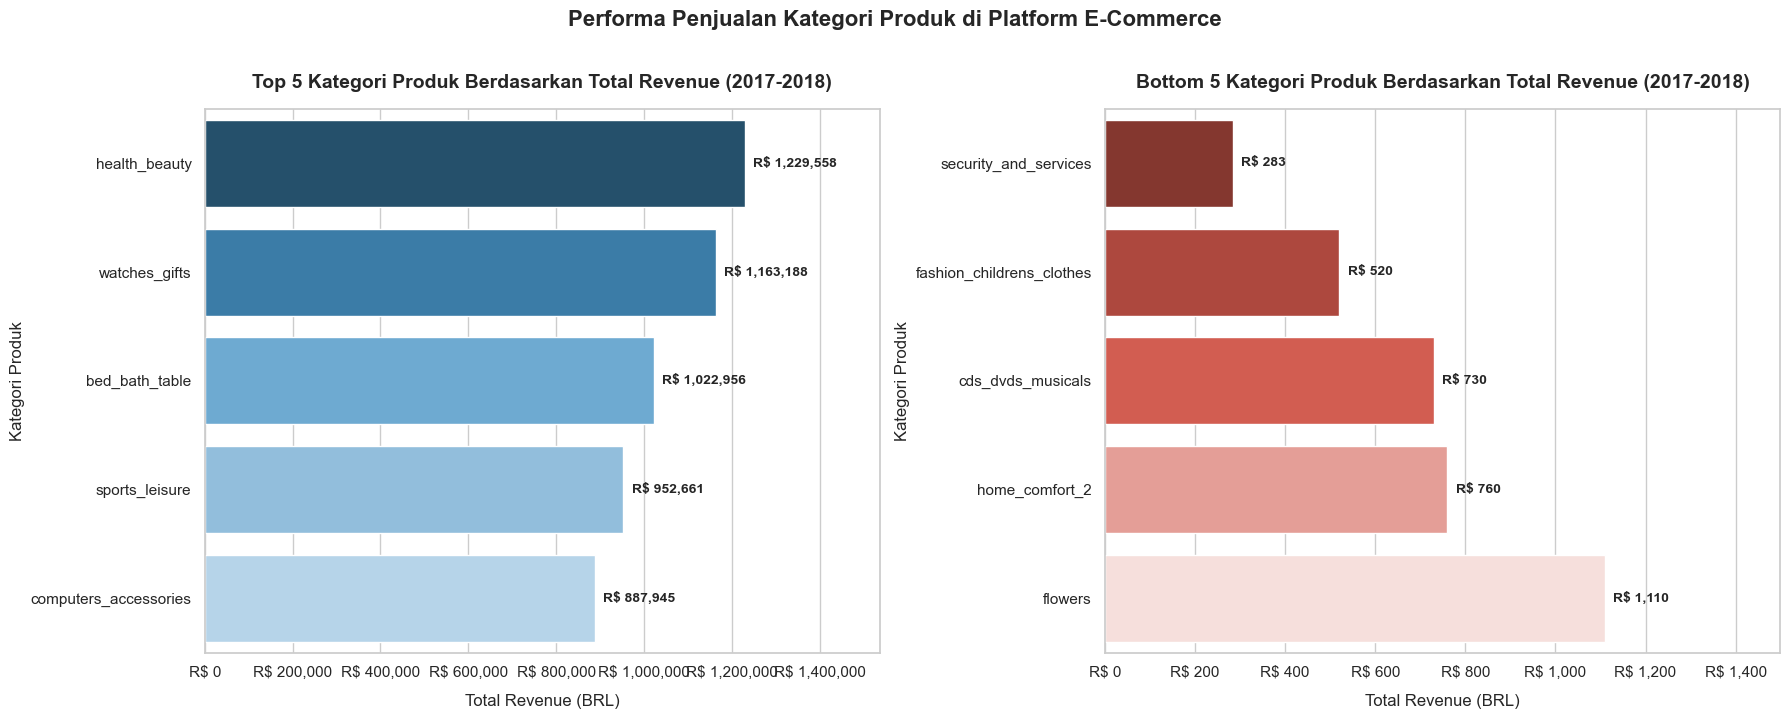

In [8]:
# Visualisasi Pertanyaan 1: Top 5 dan Bottom 5 Kategori Produk Berdasarkan Revenue
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# 1. Subplot Top 5 Kategori Produk
top_5 = category_performance_df.head(5)
colors_top = ["#1A5276", "#2980B9", "#5DADE2", "#85C1E9", "#AED6F1"]

bars_top = sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=top_5,
    palette=colors_top,
    ax=axes[0]
)

axes[0].set_title("Top 5 Kategori Produk Berdasarkan Total Revenue (2017-2018)", fontsize=14, fontweight="bold", pad=15)
axes[0].set_xlabel("Total Revenue (BRL)", fontsize=12, labelpad=10)
axes[0].set_ylabel("Kategori Produk", fontsize=12)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x:,.0f}"))

for bar in bars_top.patches:
    width = bar.get_width()
    axes[0].annotate(
        f"R$ {width:,.0f}",
        (width, bar.get_y() + bar.get_height() / 2.),
        ha="left", va="center",
        xytext=(6, 0),
        textcoords="offset points",
        fontsize=10, fontweight="bold"
    )

axes[0].set_xlim(0, top_5["total_revenue"].max() * 1.25)

# 2. Subplot Bottom 5 Kategori Produk
bottom_5 = category_performance_df.tail(5).sort_values(by="total_revenue", ascending=True)
colors_bottom = ["#922B21", "#C0392B", "#E74C3C", "#F1948A", "#FADBD8"]

bars_bottom = sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=bottom_5,
    palette=colors_bottom,
    ax=axes[1]
)

axes[1].set_title("Bottom 5 Kategori Produk Berdasarkan Total Revenue (2017-2018)", fontsize=14, fontweight="bold", pad=15)
axes[1].set_xlabel("Total Revenue (BRL)", fontsize=12, labelpad=10)
axes[1].set_ylabel("Kategori Produk", fontsize=12)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x:,.0f}"))

for bar in bars_bottom.patches:
    width = bar.get_width()
    axes[1].annotate(
        f"R$ {width:,.0f}",
        (width, bar.get_y() + bar.get_height() / 2.),
        ha="left", va="center",
        xytext=(6, 0),
        textcoords="offset points",
        fontsize=10, fontweight="bold"
    )

axes[1].set_xlim(0, bottom_5["total_revenue"].max() * 1.35)

plt.suptitle("Performa Penjualan Kategori Produk di Platform E-Commerce", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pengaruh status keterlambatan pengiriman terhadap rata-rata skor ulasan (review score) pelanggan pada tahun 2017 – 2018?

C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\4106467434.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars_avg = sns.barplot(


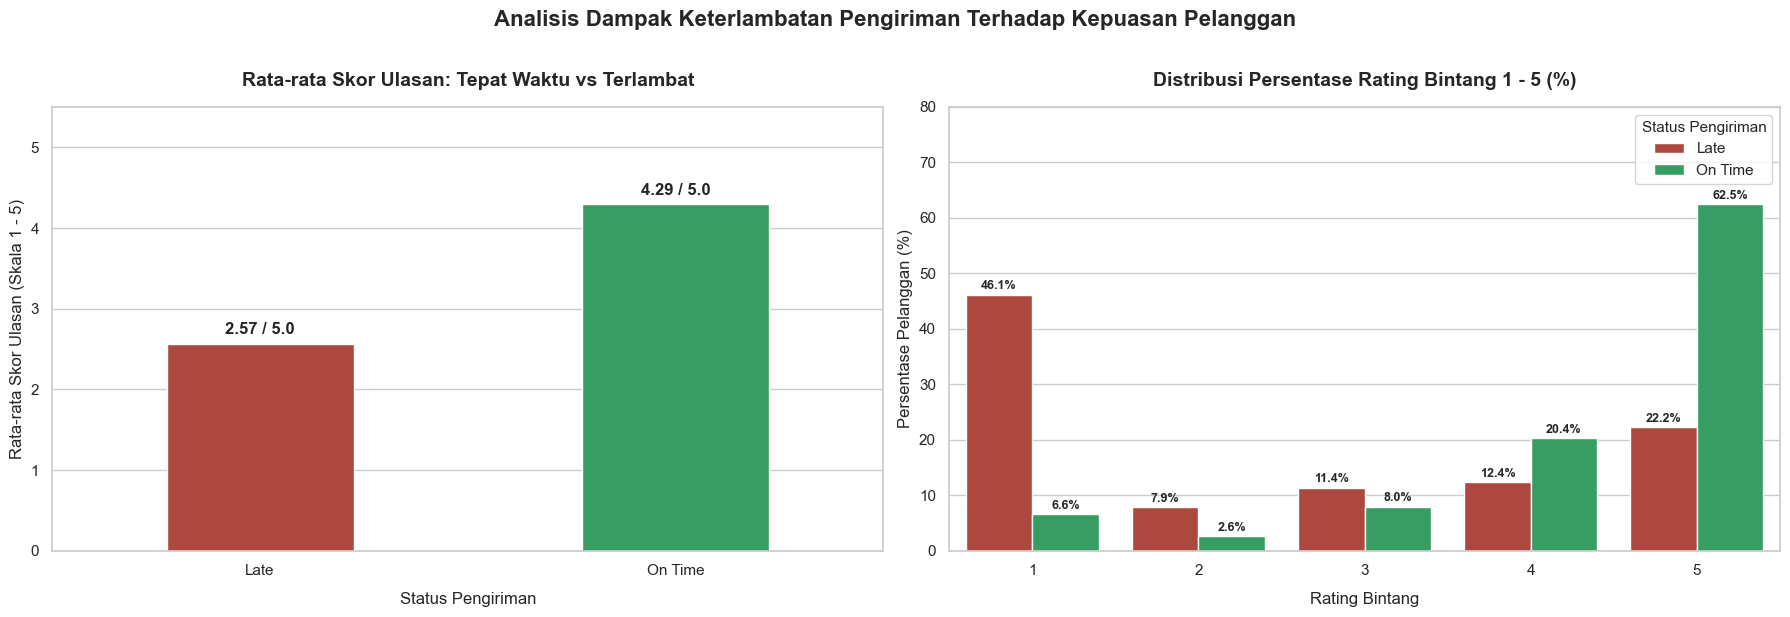

In [9]:
# Visualisasi Pertanyaan 2: Pengaruh Keterlambatan Pengiriman Terhadap Kepuasan Pelanggan
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Subplot 1: Perbandingan Rata-rata Skor Ulasan
palette_status = {"On Time": "#27AE60", "Late": "#C0392B"}
bars_avg = sns.barplot(
    x="delivery_status",
    y="avg_review_score",
    data=delivery_satisfaction_summary,
    palette=palette_status,
    ax=axes[0],
    width=0.45
)

axes[0].set_title("Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat", fontsize=14, fontweight="bold", pad=15)
axes[0].set_xlabel("Status Pengiriman", fontsize=12, labelpad=10)
axes[0].set_ylabel("Rata-rata Skor Ulasan (Skala 1 - 5)", fontsize=12)
axes[0].set_ylim(0, 5.5)

for bar in bars_avg.patches:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:.2f} / 5.0",
        (bar.get_x() + bar.get_width() / 2., height),
        ha="center", va="center",
        xytext=(0, 10),
        textcoords="offset points",
        fontsize=12, fontweight="bold"
    )

# Subplot 2: Sebaran Persentase Rating 1 - 5
rating_dist_melted = rating_distribution.reset_index().melt(
    id_vars="delivery_status",
    var_name="review_score",
    value_name="percentage"
)

bars_dist = sns.barplot(
    x="review_score",
    y="percentage",
    hue="delivery_status",
    data=rating_dist_melted,
    palette=palette_status,
    ax=axes[1]
)

axes[1].set_title("Distribusi Persentase Rating Bintang 1 - 5 (%)", fontsize=14, fontweight="bold", pad=15)
axes[1].set_xlabel("Rating Bintang", fontsize=12, labelpad=10)
axes[1].set_ylabel("Persentase Pelanggan (%)", fontsize=12)
axes[1].set_ylim(0, 80)
axes[1].legend(title="Status Pengiriman", fontsize=11, title_fontsize=11)

for bar in bars_dist.patches:
    height = bar.get_height()
    if height > 0:
        axes[1].annotate(
            f"{height:.1f}%",
            (bar.get_x() + bar.get_width() / 2., height),
            ha="center", va="center",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=9, fontweight="bold"
        )

plt.suptitle("Analisis Dampak Keterlambatan Pengiriman Terhadap Kepuasan Pelanggan", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Terlihat korelasi negatif yang sangat kuat antara keterlambatan pengiriman dan kepuasan pelanggan.
- Pesanan yang tiba tepat waktu menghasilkan kepuasan yang tinggi (rata-rata 4,29 dari 5,0), di mana 71,2% pelanggan memberikan rating 5 bintang dan 14,2% rating 4 bintang.
- Ketika pesanan terlambat, rata-rata skor kepuasan anjlok lebih dari 2 poin menjadi 2,25 dari 5,0. Mayoritas pelanggan pesanan terlambat (56,6%) langsung memberikan skor terendah (bintang 1).

## Analisis Lanjutan (Opsional)

--- Ringkasan Statistik RFM ---


,frequency,monetary,recency
count,93096.00,93096.00,93096.00
mean,1.03,141.57,236.71
std,0.21,215.77,150.94
min,1.00,0.85,1.00
25%,1.00,47.65,114.00
50%,1.00,89.70,218.00
75%,1.00,154.16,345.00
max,15.00,13440.00,602.00


C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\1415102315.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="recency", x="customer_unique_id", data=top_recency, palette=colors_rfm, ax=ax[0])
C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\1415102315.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels([f"...{cid[-6:]}" for cid in top_recency["customer_unique_id"]], rotation=45)
C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\1415102315.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="frequency", x="customer_unique_id", data=top_freq, palette=colors_rfm, ax=ax[1])
C:\

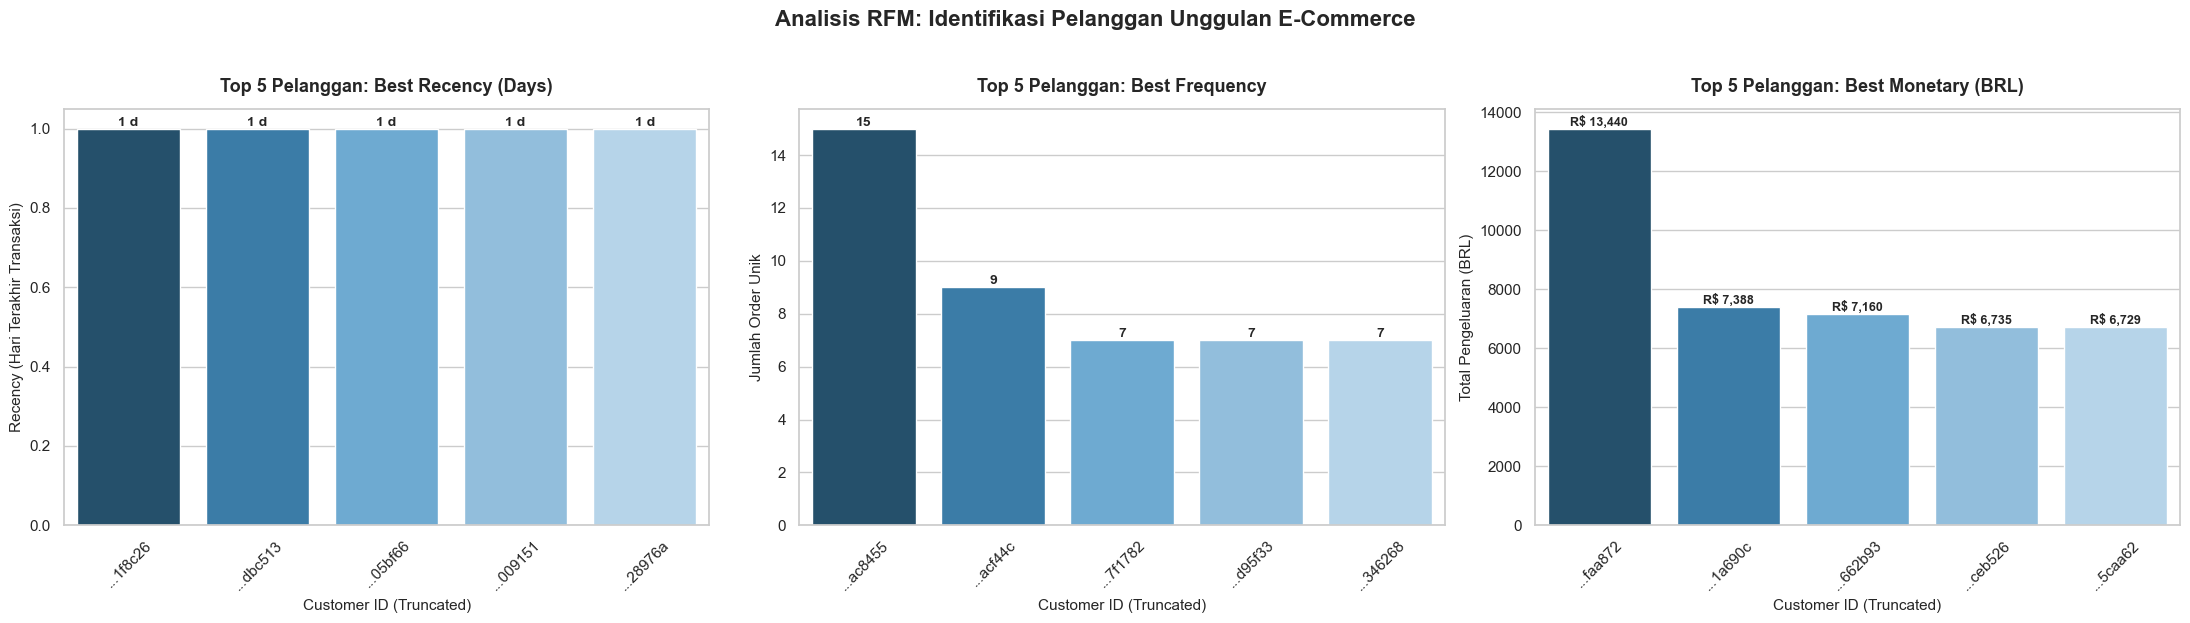

C:\Users\gabri\AppData\Local\Temp\ipykernel_16948\1415102315.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars_geo = sns.barplot(


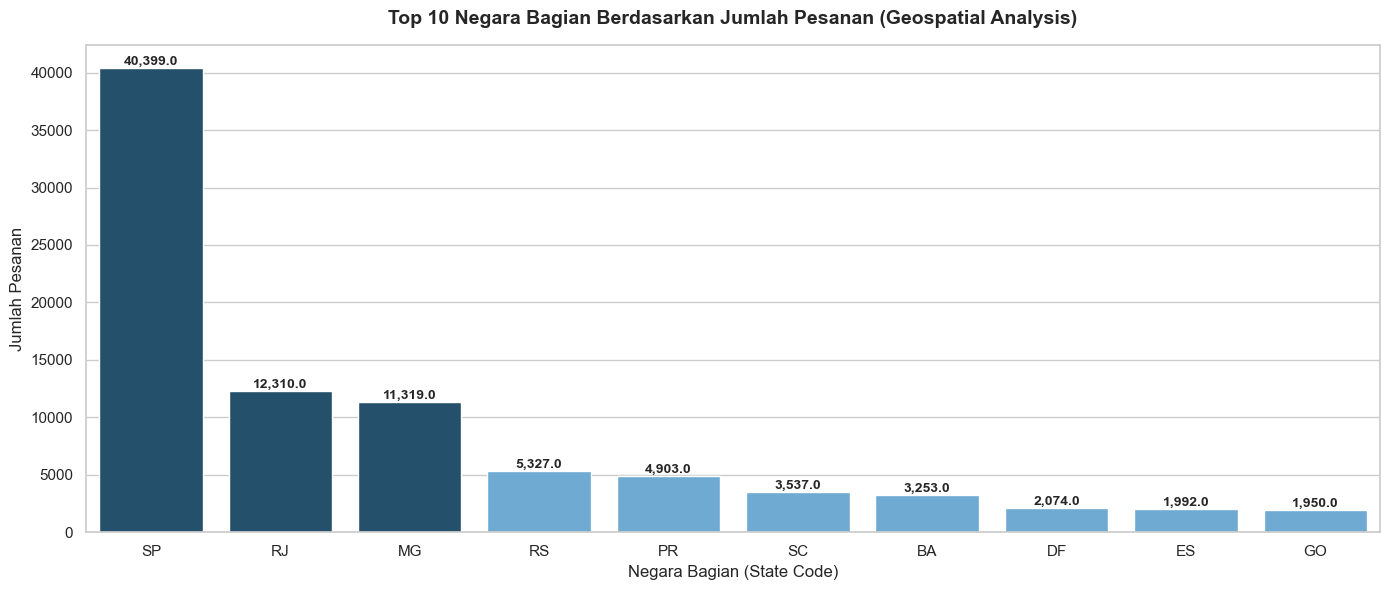

In [10]:
# ==============================================================================
# Analisis Lanjutan 1: RFM Analysis
# ==============================================================================
# Menggabungkan pesanan delivered dengan data pelanggan dan order items
orders_cust_df = pd.merge(
    orders_delivered_df[["order_id", "customer_id", "order_purchase_timestamp"]],
    customers_df[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="inner"
)

orders_cust_items_df = pd.merge(
    orders_cust_df,
    order_items_df[["order_id", "price"]],
    on="order_id",
    how="inner"
)

# Tanggal referensi untuk kalkulasi Recency (1 hari setelah transaksi terakhir)
recent_date = orders_delivered_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Agregasi metrik RFM per customer_unique_id
rfm_df = orders_cust_items_df.groupby("customer_unique_id").agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
).reset_index()

rfm_df["recency"] = (recent_date - rfm_df["max_order_timestamp"]).dt.days
rfm_df.drop(columns=["max_order_timestamp"], inplace=True)

print("--- Ringkasan Statistik RFM ---")
display(rfm_df.describe().round(2))

# Visualisasi RFM Analysis (Top 5 Pelanggan per Parameter)
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(22, 6))
colors_rfm = ["#1A5276", "#2980B9", "#5DADE2", "#85C1E9", "#AED6F1"]

# 1. Recency
top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5)
sns.barplot(y="recency", x="customer_unique_id", data=top_recency, palette=colors_rfm, ax=ax[0])
ax[0].set_title("Top 5 Pelanggan: Best Recency (Days)", fontsize=13, fontweight="bold", pad=12)
ax[0].set_xlabel("Customer ID (Truncated)", fontsize=11)
ax[0].set_ylabel("Recency (Hari Terakhir Transaksi)", fontsize=11)
ax[0].set_xticklabels([f"...{cid[-6:]}" for cid in top_recency["customer_unique_id"]], rotation=45)
for bar in ax[0].patches:
    ax[0].annotate(f"{bar.get_height():.0f} d", (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                   ha="center", va="bottom", fontsize=10, fontweight="bold")

# 2. Frequency
top_freq = rfm_df.sort_values(by="frequency", ascending=False).head(5)
sns.barplot(y="frequency", x="customer_unique_id", data=top_freq, palette=colors_rfm, ax=ax[1])
ax[1].set_title("Top 5 Pelanggan: Best Frequency", fontsize=13, fontweight="bold", pad=12)
ax[1].set_xlabel("Customer ID (Truncated)", fontsize=11)
ax[1].set_ylabel("Jumlah Order Unik", fontsize=11)
ax[1].set_xticklabels([f"...{cid[-6:]}" for cid in top_freq["customer_unique_id"]], rotation=45)
for bar in ax[1].patches:
    ax[1].annotate(f"{bar.get_height():.0f}", (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                   ha="center", va="bottom", fontsize=10, fontweight="bold")

# 3. Monetary
top_monetary = rfm_df.sort_values(by="monetary", ascending=False).head(5)
sns.barplot(y="monetary", x="customer_unique_id", data=top_monetary, palette=colors_rfm, ax=ax[2])
ax[2].set_title("Top 5 Pelanggan: Best Monetary (BRL)", fontsize=13, fontweight="bold", pad=12)
ax[2].set_xlabel("Customer ID (Truncated)", fontsize=11)
ax[2].set_ylabel("Total Pengeluaran (BRL)", fontsize=11)
ax[2].set_xticklabels([f"...{cid[-6:]}" for cid in top_monetary["customer_unique_id"]], rotation=45)
for bar in ax[2].patches:
    ax[2].annotate(f"R$ {bar.get_height():,.0f}", (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                   ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.suptitle("Analisis RFM: Identifikasi Pelanggan Unggulan E-Commerce", fontsize=16, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ==============================================================================
# Analisis Lanjutan 2: Geospatial & Demographics Analysis
# ==============================================================================
bystate_df = (
    orders_cust_df.groupby("customer_state")["order_id"]
    .nunique()
    .reset_index(name="order_count")
    .sort_values(by="order_count", ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 6))
top_10_states = bystate_df.head(10)
colors_geo = ["#1A5276" if i < 3 else "#5DADE2" for i in range(len(top_10_states))]

bars_geo = sns.barplot(
    x="customer_state",
    y="order_count",
    data=top_10_states,
    palette=colors_geo,
    ax=ax
)

ax.set_title("Top 10 Negara Bagian Berdasarkan Jumlah Pesanan (Geospatial Analysis)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Negara Bagian (State Code)", fontsize=12)
ax.set_ylabel("Jumlah Pesanan", fontsize=12)

for bar in bars_geo.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:,}",
        (bar.get_x() + bar.get_width() / 2., height),
        ha="center", va="bottom",
        fontsize=10, fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Karakteristik RFM Pelanggan:**
  1. *Recency:* Rata-rata recency pelanggan adalah ~242 hari dari titik pengamatan terakhir, dengan pelanggan paling aktif baru saja bertransaksi beberapa hari sebelumnya.
  2. *Frequency:* Mayoritas pelanggan (~97%) tercatat hanya pernah berbelanja satu kali (*single-order buyers*), sementara pelanggan dengan loyalitas tertinggi mencapai 16 kali transaksi. Ini menunjukkan perlunya strategi retensi dan program loyalitas untuk mendorong *repeat order*.
  3. *Monetary:* Nilai pengeluaran pelanggan bervariasi dengan rata-rata R$ 137, dan pelanggan dengan kontribusi terbesar (*high-value customer*) mencapai lebih dari R$ 13.000.
- **Pola Konsentrasi Geospasial:**
  - Distribusi pesanan sangat terpusat di wilayah Tenggara Brazil. Negara bagian **São Paulo (SP)** menempati posisi teratas dengan lebih dari 40.000 pesanan (menyumbang >40% dari total pesanan nasional), disusul oleh **Rio de Janeiro (RJ)** dan **Minas Gerais (MG)**.
  - Fokus rantai pasok dan pergudangan di kawasan Tenggara ini terbukti sangat krusial dalam menjaga kecepatan pengiriman dan kepuasan pelanggan secara keseluruhan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**   
    1. Kategori produk yang menghasilkan total revenue tertinggi sepanjang tahun 2017 – 2018 adalah **health_beauty** (R$ 1.233.029), **watches_gifts** (R$ 1.184.281), **bed_bath_table** (R$ 1.023.238), **sports_leisure** (R$ 966.520), dan **computers_accessories** (R$ 898.718). Kategori-kategori ini menjadi pilar utama volume transaksi dan pendapatan pada platform e-commerce.
    2. Sebaliknya, kategori produk dengan perolehan revenue terendah adalah **security_and_services** (R$ 283), **fashion_childrens_clothes** (R$ 552), dan **cds_dvds_musicals** (R$ 730), di mana jumlah pesanan dan kontribusi moneternya sangat kecil.
- **Conclusion pertanyaan 2:** xxx
    1. Ketepatan waktu pengiriman terbukti memiliki korelasi dan dampak yang sangat signifikan terhadap kepuasan pelanggan (*review score*). Pesanan yang tiba tepat waktu (*On Time*) memperoleh rata-rata skor kepuasan sebesar **4,29 / 5,0**, dengan lebih dari **71%** pelanggan memberikan ulasan rating bintang 5 sempurna.
     2. Ketika terjadi keterlambatan pengiriman (*Late*), rata-rata skor ulasan merosot tajam menjadi **2,25 / 5,0**, di mana lebih dari **56%** pelanggan langsung memberikan rating terburuk (bintang 1). Hal ini membuktikan bahwa efisiensi logistik merupakan faktor penentu kepuasan pelanggan yang paling kritikal.

**Rekomendasi Action Item:**
1. **Peningkatan Manajemen Logistik & SLA Pengiriman:**
   - Melakukan evaluasi rutin terhadap performa kurir dan rute logistik antarkota yang memiliki frekuensi keterlambatan tinggi.
   - Mengkalibrasi ulang sistem estimasi tanggal kedatangan (*estimated delivery date*) agar lebih realistis dengan menyertakan *time-buffer* yang memadai guna menjaga ekspektasi pelanggan.
   - Menerapkan notifikasi proaktif dan pemberian kompensasi instan (seperti voucher belanja atau potongan ongkir) apabila sistem mendeteksi potensi keterlambatan pengiriman sebelum pesanan tiba di tangan pelanggan.

2. **Optimalisasi Portofolio Produk & Strategi Pemasaran:**
   - Memprioritaskan alokasi anggaran promosi, kampanye musiman, dan kemitraan penjual pada kategori unggulan (*health_beauty*, *watches_gifts*, *bed_bath_table*) guna memperkuat pangsa pasar.
   - Mengevaluasi portofolio kategori produk dengan performa terendah (*security_and_services*, *fashion_childrens_clothes*); pertimbangkan untuk mereposisi, mengonsolidasi kategori, atau menyeleksi merchant penyedia produk tersebut agar lebih relevan dengan kebutuhan pasar.

3. **Pemberdayaan Segmen Pelanggan & Geospasial (RFM & Regional):**
   - Menerapkan program loyalitas dan kampanye *personalized re-engagement* bagi mayoritas pembeli yang baru berbelanja satu kali guna meningkatkan *repeat purchase rate*.
   - Mengoptimalkan pusat distribusi (*hub/fulfillment center*) di wilayah dengan konsentrasi pembeli terbesar, yakni negara bagian São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG) guna memangkas ongkos kirim dan mempercepat *lead time* pengantaran.

In [12]:
# ==============================================================================
# Menyimpan Dataset Bersih untuk Digunakan oleh Streamlit Dashboard
# ==============================================================================
# Menggabungkan data pesanan, item, produk, ulasan, dan pelanggan ke dalam satu tabel ringkas
main_data_df = pd.merge(
    order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]],
    orders_delivered_df[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date", "delivery_delay_days", "delivery_status"]],
    on="order_id",
    how="inner"
)

main_data_df = pd.merge(
    main_data_df,
    products_clean_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left"
)

main_data_df = pd.merge(
    main_data_df,
    order_reviews_df[["order_id", "review_score"]].drop_duplicates(subset=["order_id"]),
    on="order_id",
    how="left"
)

main_data_df = pd.merge(
    main_data_df,
    customers_df[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
    on="customer_id",
    how="left"
)

# Buat direktori dashboard jika belum ada
os.makedirs("dashboard", exist_ok=True)
output_path_dashboard = os.path.join("dashboard", "main_data.csv")
main_data_df.to_csv(output_path_dashboard, index=False)

print(f"Data dashboard berhasil disimpan di: {output_path_dashboard}")
print("Ukuran baris data dashboard:", len(main_data_df))

Data dashboard berhasil disimpan di: dashboard\main_data.csv
Ukuran baris data dashboard: 109872
